# 🏏 IPL Win Predictor: Data Cleaning & Exploratory Data Analysis

This notebook walks through the data extraction, cleaning, and exploratory data analysis of the Cricsheet IPL ball-by-ball JSON dataset.

### Objectives:
1. Understand the raw JSON structure of Cricsheet match files.
2. Filter out non-standard matches (rain/DLS, ties, super overs, truncated overs).
3. Standardize franchise names across 17 IPL seasons.
4. Correctly track legal deliveries vs. extras (wides/no-balls) and enforce mathematical guards (e.g. CRR at ball 0 = 0).
5. Conduct Exploratory Data Analysis (EDA) on chasing dynamics.


In [1]:
import os
import sys
import glob
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Canonical franchise normalization mapping
TEAM_NORMALIZATION = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
}

def normalize_team(name: str) -> str:
    return TEAM_NORMALIZATION.get(name, name)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


## 1. Inspecting Raw Cricsheet Match JSON Structure

In [2]:
json_files = glob.glob('../ipl_json/*.json')
print(f"Total raw JSON files found: {len(json_files)}")

# Inspect a sample match file
sample_file = json_files[0]
with open(sample_file, 'r', encoding='utf-8') as f:
    sample_data = json.load(f)

print(f"Match File: {os.path.basename(sample_file)}")
print("Top-level keys:", list(sample_data.keys()))
print("\nInfo keys:", list(sample_data['info'].keys()))
print(f"Teams: {sample_data['info'].get('teams')}")
print(f"Venue: {sample_data['info'].get('venue')}")
print(f"Outcome: {sample_data['info'].get('outcome')}")
print(f"Number of Innings: {len(sample_data.get('innings', []))}")


Total raw JSON files found: 1243
Match File: 1082591.json
Top-level keys: ['meta', 'info', 'innings']

Info keys: ['balls_per_over', 'city', 'dates', 'event', 'gender', 'match_type', 'officials', 'outcome', 'overs', 'player_of_match', 'players', 'registry', 'season', 'team_type', 'teams', 'toss', 'venue']
Teams: ['Sunrisers Hyderabad', 'Royal Challengers Bangalore']
Venue: Rajiv Gandhi International Stadium, Uppal
Outcome: {'by': {'runs': 35}, 'winner': 'Sunrisers Hyderabad'}
Number of Innings: 2


## 2. Team Name Normalization
Over 17 IPL editions, several franchises have rebranded or experienced minor naming variations in data logs.
Here is the mapping applied across all records:


In [3]:
df_inn1 = pd.read_csv('../data/processed/innings1_ballbyball.csv', low_memory=False)
df_chases = pd.read_csv('../data/processed/chases_ballbyball.csv', low_memory=False)
df_meta = pd.read_csv('../data/processed/matches_metadata.csv')

print(f'Cleaned Regulation Matches:              {len(df_meta):,}')
print(f'1st Innings Delivery Snapshots (Target Setting): {len(df_inn1):,}')
print(f'2nd Innings Delivery Snapshots (Target Chasing): {len(df_chases):,}')
print(f'Total Full-Match Deliveries:             {len(df_inn1) + len(df_chases):,}')


Cleaned Regulation Matches:              1,185
1st Innings Delivery Snapshots (Target Setting): 147,937
2nd Innings Delivery Snapshots (Target Chasing): 137,887
Total Full-Match Deliveries:             285,824


In [4]:
def parse_cricsheet_json(json_dir="../ipl_json"):
    """
    Self-contained extraction function that processes raw Cricsheet JSONs,
    filters non-standard games, and builds the ball-by-ball dataset.
    """
    json_files = sorted(glob.glob(os.path.join(json_dir, "*.json")))
    matches_meta = []
    chases_records = []

    for file_path in json_files:
        match_id = os.path.splitext(os.path.basename(file_path))[0]
        with open(file_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        info = data.get("info", {})
        outcome = info.get("outcome", {})
        innings = data.get("innings", [])

        # Filter criteria
        if len(innings) < 2: continue
        if outcome.get("result") in ["no result", "tie"]: continue
        if len(innings) > 2 or outcome.get("eliminator") is not None: continue
        if outcome.get("method") in ["D/L", "DLS"]: continue

        inn2 = innings[1]
        target_info = inn2.get("target", {})
        target_runs = target_info.get("runs")
        target_overs = target_info.get("overs")

        if not target_runs: continue
        if target_overs is not None and target_overs < 20: continue

        raw_winner = outcome.get("winner")
        if not raw_winner: continue

        outcome_winner = normalize_team(raw_winner)
        batting_team = normalize_team(inn2.get("team"))
        teams = [normalize_team(t) for t in info.get("teams", [])]
        bowling_team = teams[0] if teams[1] == batting_team else teams[1] if len(teams) == 2 else "Unknown"

        batting_team_won = 1 if outcome_winner == batting_team else 0

        # Ball by ball accumulator
        current_score = 0
        legal_balls_bowled = 0
        wickets_fallen = 0
        delivery_seq = 0

        for over in inn2.get("overs", []):
            for delivery in over.get("deliveries", []):
                delivery_seq += 1
                runs_left = max(0, target_runs - current_score)
                balls_left = max(0, 120 - legal_balls_bowled)
                wickets_in_hand = max(0, 10 - wickets_fallen)

                crr = 0.0 if legal_balls_bowled == 0 else (current_score * 6.0) / legal_balls_bowled
                rrr = 0.0 if runs_left <= 0 else min(36.0, (runs_left * 6.0) / max(1, balls_left))

                chases_records.append({
                    "match_id": match_id,
                    "season": str(info.get("season", "")),
                    "batting_team": batting_team,
                    "bowling_team": bowling_team,
                    "venue": info.get("venue", "Unknown"),
                    "target": target_runs,
                    "current_score": current_score,
                    "runs_left": runs_left,
                    "legal_balls_bowled": legal_balls_bowled,
                    "balls_left": balls_left,
                    "wickets_in_hand": wickets_in_hand,
                    "crr": round(crr, 4),
                    "rrr": round(rrr, 4),
                    "batting_team_won": batting_team_won
                })

                extras = delivery.get("extras", {})
                is_wide = "wides" in extras
                is_noball = "noballs" in extras
                current_score += delivery.get("runs", {}).get("total", 0)
                if not (is_wide or is_noball): legal_balls_bowled += 1
                if "wickets" in delivery: wickets_fallen += len(delivery["wickets"])

                if current_score >= target_runs or wickets_fallen >= 10 or legal_balls_bowled >= 120:
                    break
            if current_score >= target_runs or wickets_fallen >= 10 or legal_balls_bowled >= 120:
                break

    return pd.DataFrame(chases_records)

print("Parser function ready. Cleaned CSVs are stored in ../data/processed/")


Parser function ready. Cleaned CSVs are stored in ../data/processed/


## 3. Data Cleaning & Ball Accounting Rules
To ensure a high-integrity, standard dataset:
- **Exclude DLS/Rain matches:** Avoids distorted targets and shortened innings.
- **Exclude Ties & Super Overs:** Ensures clear binary outcome labels ($y \in \{0, 1\}$).
- **Ball Accounting:**
  - Wides & No-balls: Add runs to score, do **not** decrement balls remaining.
  - Legal Deliveries (including wickets & byes): Add runs, decrement balls remaining.
- **Mathematical Guards:**
  - $\text{CRR} = 0.0$ at ball 0.
  - $\text{RRR}$ capped at 36.0 to prevent extreme outliers near the end of a chase.


In [5]:
# Load the processed metadata and chase records generated by the parser
df_meta = pd.read_csv('../data/processed/matches_metadata.csv')
df_chases = pd.read_csv('../data/processed/chases_ballbyball.csv', low_memory=False)

print(f"Valid cleaned regulation matches: {len(df_meta)}")
print(f"Total 2nd-innings delivery snapshots: {len(df_chases):,}")
print(f"Missing values count across dataset: {df_chases.isnull().sum().sum()}")


Valid cleaned regulation matches: 1185
Total 2nd-innings delivery snapshots: 137,887
Missing values count across dataset: 0


## 4. Exploratory Data Analysis (EDA)

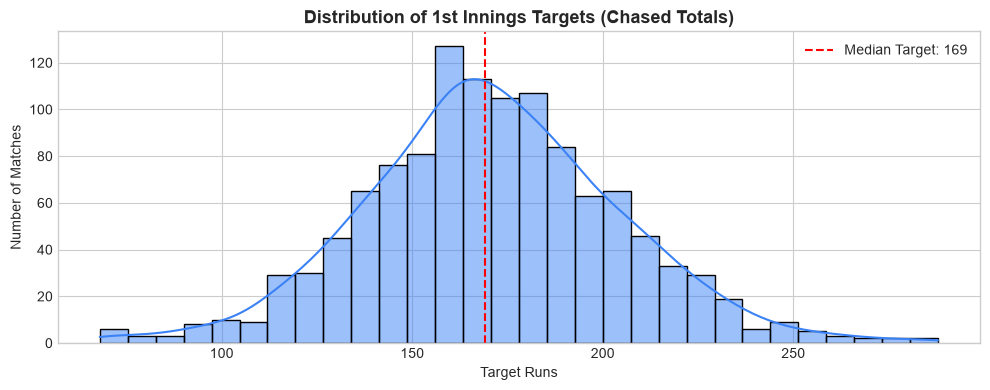

In [6]:
# 4.1 Target Score Distribution
plt.figure(figsize=(10, 4))
sns.histplot(df_meta['target'], bins=30, kde=True, color='#3B82F6')
plt.axvline(df_meta['target'].median(), color='red', linestyle='--', label=f"Median Target: {df_meta['target'].median():.0f}")
plt.title("Distribution of 1st Innings Targets (Chased Totals)", fontsize=13, fontweight='bold')
plt.xlabel("Target Runs")
plt.ylabel("Number of Matches")
plt.legend()
plt.tight_layout()
plt.show()


C:\Users\rohit\AppData\Local\Temp\ipykernel_33608\380115344.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=team_chase_stats['win_rate_pct'], y=team_chase_stats.index, palette='viridis')


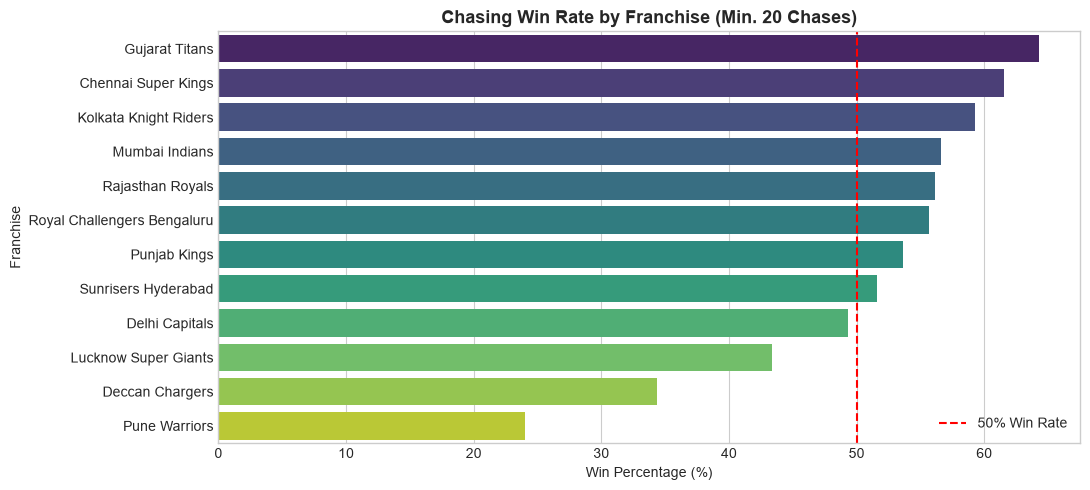

In [7]:
# 4.2 Overall Chasing Win Rate by Team
team_chase_stats = df_meta.groupby('batting_team').agg(
    total_chases=('batting_team_won', 'count'),
    chases_won=('batting_team_won', 'sum')
)
team_chase_stats['win_rate_pct'] = (team_chase_stats['chases_won'] / team_chase_stats['total_chases']) * 100
team_chase_stats = team_chase_stats[team_chase_stats['total_chases'] >= 20].sort_values('win_rate_pct', ascending=False)

plt.figure(figsize=(11, 5))
sns.barplot(x=team_chase_stats['win_rate_pct'], y=team_chase_stats.index, palette='viridis')
plt.axvline(50, color='red', linestyle='--', label='50% Win Rate')
plt.title("Chasing Win Rate by Franchise (Min. 20 Chases)", fontsize=13, fontweight='bold')
plt.xlabel("Win Percentage (%)")
plt.ylabel("Franchise")
plt.legend()
plt.tight_layout()
plt.show()


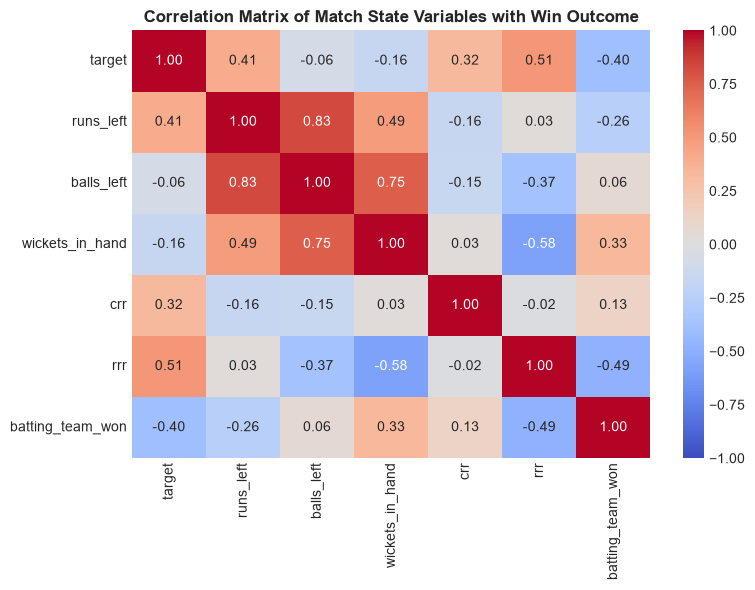

In [8]:
# 4.3 Correlation Heatmap of Core Match State Variables
numeric_cols = ['target', 'runs_left', 'balls_left', 'wickets_in_hand', 'crr', 'rrr', 'batting_team_won']
corr = df_chases[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar=True)
plt.title("Correlation Matrix of Match State Variables with Win Outcome", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


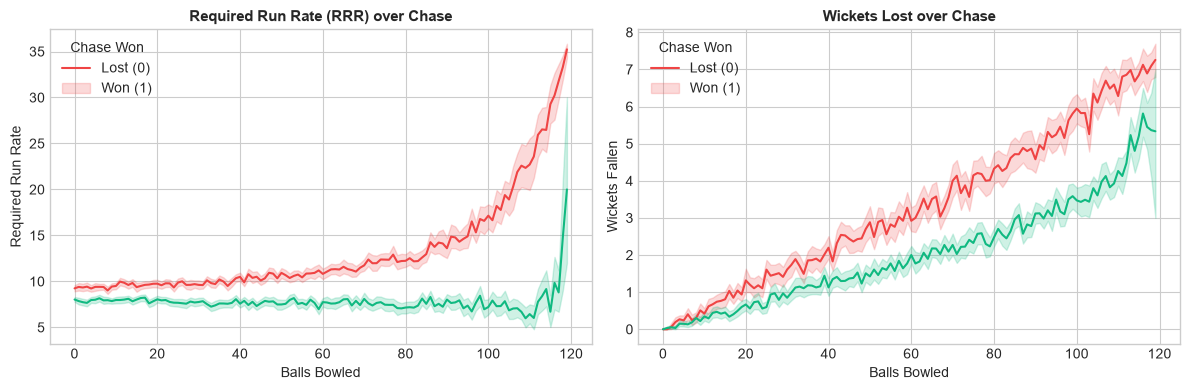

In [9]:
# 4.4 RRR and Wickets Evolution Across Innings: Won vs. Lost Chases
df_sample = df_chases.sample(n=15000, random_state=42)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.lineplot(data=df_sample, x='legal_balls_bowled', y='rrr', hue='batting_team_won', palette={0: '#EF4444', 1: '#10B981'})
plt.title("Required Run Rate (RRR) over Chase", fontsize=11, fontweight='bold')
plt.xlabel("Balls Bowled")
plt.ylabel("Required Run Rate")
plt.legend(title='Chase Won', labels=['Lost (0)', 'Won (1)'])

plt.subplot(1, 2, 2)
sns.lineplot(data=df_sample, x='legal_balls_bowled', y='wickets_fallen', hue='batting_team_won', palette={0: '#EF4444', 1: '#10B981'})
plt.title("Wickets Lost over Chase", fontsize=11, fontweight='bold')
plt.xlabel("Balls Bowled")
plt.ylabel("Wickets Fallen")
plt.legend(title='Chase Won', labels=['Lost (0)', 'Won (1)'])

plt.tight_layout()
plt.show()
